# Práctica XAI - PCD
Joaquin Negrete


In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv('data.csv', header=0, sep=',', encoding='utf-8')

X = df.drop(["no_presentado", "id_reserva"], axis=1)
y = df["no_presentado"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

## 1. Selección de variables

Para esto, voy a utilizar SelectFromModel porque no tiene sentido utilizar uno como PCA con el que se pierde interpretabilidad. Queremos ver la interpretabilidad del modelo en el punto 2, y si los datos pierden sentido, no sirve de nada. 

RFE sirve para este caso porque no perdemos interpretabilidad. 

In [2]:
from sklearn.base import clone
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lr = LogisticRegression(max_iter=1000, random_state=42)
sfm = SelectFromModel(estimator=clone(lr), threshold="median")

feature_selection = Pipeline([
    ('scaler', StandardScaler()),
    ('feature_selection', sfm),
])

feature_selection.fit(X_train, y_train)

X_train.columns[feature_selection.named_steps['feature_selection'].get_support()]

Index(['reservas_previas', 'ausencias_previas', 'cambios_reserva',
       'solicitudes_especiales', 'deposito_pagado'],
      dtype='str')

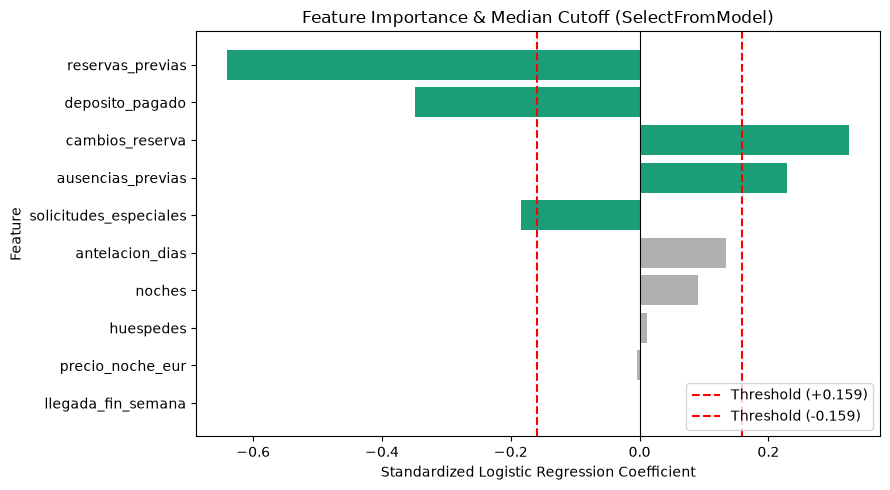

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Extract fitted SelectFromModel step
sfm = feature_selection.named_steps['feature_selection']

# sfm.estimator_ was fitted on all features before applying the threshold
coefs = sfm.estimator_.coef_[0]
features = X_train.columns
support = sfm.get_support()
threshold = sfm.threshold_  # Numeric value of the median cutoff

# Build DataFrame sorted by magnitude
df = pd.DataFrame({
    'Feature': features,
    'Coefficient': coefs,
    'Abs_Importance': np.abs(coefs),
    'Selected': np.where(support, 'Kept (>= Median)', 'Dropped (< Median)')
}).sort_values(by='Abs_Importance', ascending=True)

# Plot
plt.figure(figsize=(9, 5))

# Color bars by selection status
colors = ['#1b9e77' if s == 'Kept (>= Median)' else '#b0b0b0' for s in df['Selected']]
plt.barh(df['Feature'], df['Coefficient'], color=colors)

# Reference lines
plt.axvline(0, color='black', linestyle='-', linewidth=0.8)
plt.axvline(threshold, color='red', linestyle='--', label=f'Threshold (+{threshold:.3f})')
plt.axvline(-threshold, color='red', linestyle='--', label=f'Threshold (-{threshold:.3f})')

plt.xlabel('Standardized Logistic Regression Coefficient')
plt.ylabel('Feature')
plt.title('Feature Importance & Median Cutoff (SelectFromModel)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [4]:
X_train_extracted = feature_selection.transform(X_train)
X_test_extracted = feature_selection.transform(X_test)

## 2. Un modelo interpretable

Para este caso no es buena idea utilizar un árbol de decisión, por el simple hecho de que como las clases están desbalanceadas, incluso con 4 niveles el árbol sigue poniendo todas las hojas en la misma clase. Más de 4 niveles es muy difícil de visualizar. Por eso voy a usar una regresión logística como en la práctica pasada. 

In [5]:
from sklearn.model_selection import cross_validate

pipeline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

cv_results = cross_validate(
    pipeline_lr,
    X_train_extracted,
    y_train,
    cv=cv,
    scoring=['roc_auc', 'f1_weighted', 'balanced_accuracy'],
    return_train_score=False
)

print(f"ROC-AUC CV:           {cv_results['test_roc_auc'].mean():.4f} +/- {cv_results['test_roc_auc'].std():.4f}")
print(f"Balanced Accuracy CV: {cv_results['test_balanced_accuracy'].mean():.4f}")

pipeline_lr.fit(X_train_extracted, y_train)

ROC-AUC CV:           0.7424 +/- 0.0109
Balanced Accuracy CV: 0.6783


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


Coeficientes y odds ratios
               Feature  Coefficient  Odds_Ratio  Abs_Importance
solicitudes_especiales    -0.194777    0.823019        0.194777
     ausencias_previas     0.226516    1.254222        0.226516
       cambios_reserva     0.315368    1.370763        0.315368
       deposito_pagado    -0.350905    0.704050        0.350905
      reservas_previas    -0.678068    0.507597        0.678068


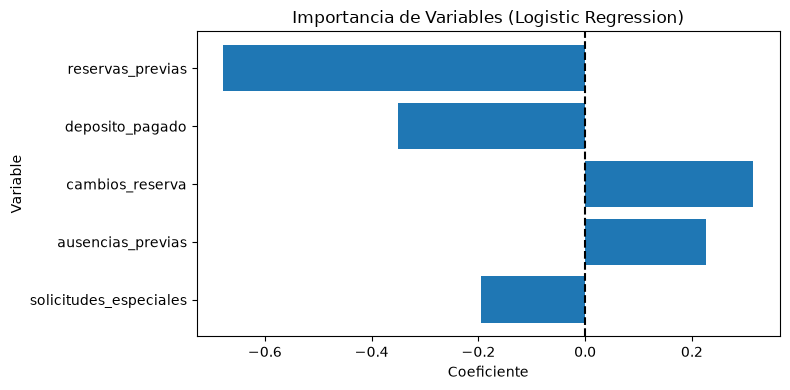

In [6]:
coefs = pipeline_lr.named_steps['classifier'].coef_[0]
features = X_train.columns[feature_selection.named_steps['feature_selection'].get_support()]

df = pd.DataFrame({
    'Feature': features,
    'Coefficient': coefs,
    'Odds_Ratio': np.exp(coefs),
    'Abs_Importance': np.abs(coefs)
}).sort_values(by='Abs_Importance', ascending=True)

print("Coeficientes y odds ratios")
print(df.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.barh(df['Feature'], df['Coefficient'])
plt.axvline(0, color='black', linestyle='--')
plt.xlabel('Coeficiente')
plt.ylabel('Variable')
plt.title('Importancia de Variables (Logistic Regression)')
plt.tight_layout()
plt.show()

Para interpretar estos resultados, primero hay que explicar qué estamos graficando y qué significa el signo. 

Para empezar, estamos graficando el coeficiente asociado a la variable dentro de la regresión logística. Nos interesa ver valores altos en valor absoluto, sin importar el signo, ya que mientras más alto, más importancia le está dando el modelo a esa variable. 

Luego, el signo. El signo indica el tipo de correlación que tiene esa variable con la variable objetivo. Es decir, si el signo del coeficiente es positivo, un mayor valor en esa variable aumenta la probabilidad de que la variable objetivo sea positiva. Por otro lado, un coeficiente negativo indica que cuanto más grande es el valor de esa variable, aumenta la probabilidad de que la variable objetivo sea negativa. 

Finalmente, el ODDS Ratio, u OR. Esto es el coeficiente exponenciado, y es una medida que indica cuánto crece la ventaja ($\frac{P}{1-P}$) de la variable objetivo a pertenecer a la clase positiva cuando la variable asociada al coeficiente aumenta en una desviación estándar. Al ser una exponencial, no nos fijamos en el signo, sino en si es mayor o menor que 1. 

En este caso, la variable de mayor importancia es reservas previas, con un signo negativo. Esto tiene sentido, pues recordemos que la variable objetivo es 0 cuando el cliente si se presenta. Entonces tiene sentido que un cliente "fiel" sea más probable que se presente que uno que no lo es. Y también vemos que es la variable con menor OR, que va de acuerdo a lo explicado anteriormente. 

## 3. Un modelo no interpretable y SHAP

El ejemplo clásico de un modelo no interpretable es un MLP. Vamos a utilizar todas las características en este caso. 

In [7]:
import joblib
from pathlib import Path
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report

ARTIFACTS_PATH = Path("artifacts")

try:
    pipeline_mlp = joblib.load(ARTIFACTS_PATH / "mlp_data.pkl", mmap_mode="r")
except FileNotFoundError:
    mlp = MLPClassifier(hidden_layer_sizes=(128, 128), learning_rate="adaptive", random_state=42, max_iter=1000)
    pipeline_mlp = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', mlp)
    ])
    pipeline_mlp.fit(X_train, y_train)
    joblib.dump(pipeline_mlp, ARTIFACTS_PATH / "mlp_data.pkl")

print(classification_report(y_test, pipeline_mlp.predict(X_test)))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97      1380
           1       0.66      0.62      0.64       120

    accuracy                           0.94      1500
   macro avg       0.82      0.80      0.81      1500
weighted avg       0.94      0.94      0.94      1500



In [8]:
def f(x):
    if not isinstance(x, pd.DataFrame):
        x = pd.DataFrame(x, columns=X_train.columns)
    return pipeline_mlp.predict_proba(x)

In [9]:
import shap

try:
    shap_data = joblib.load(ARTIFACTS_PATH / "shap_data.pkl")
    explainer = shap_data["explainer"]
    shap_values = shap_data["shap_values"]
    X_eval = shap_data["X_eval"]
except FileNotFoundError:
    X_bg = shap.sample(X_train, 100, random_state=42)
    explainer = shap.KernelExplainer(f, X_bg)

    X_eval = shap.sample(X_test, 600, random_state=42)
    shap_values = explainer(X_eval)

    obj = {
        "explainer": explainer,
        "shap_values": shap_values,
        "X_eval": X_eval
    }

    joblib.dump(obj, ARTIFACTS_PATH / "shap_data.pkl")

In [10]:
shap_values_class_1 = shap_values[:, :, 1]  # Class 1 (no_presentado)

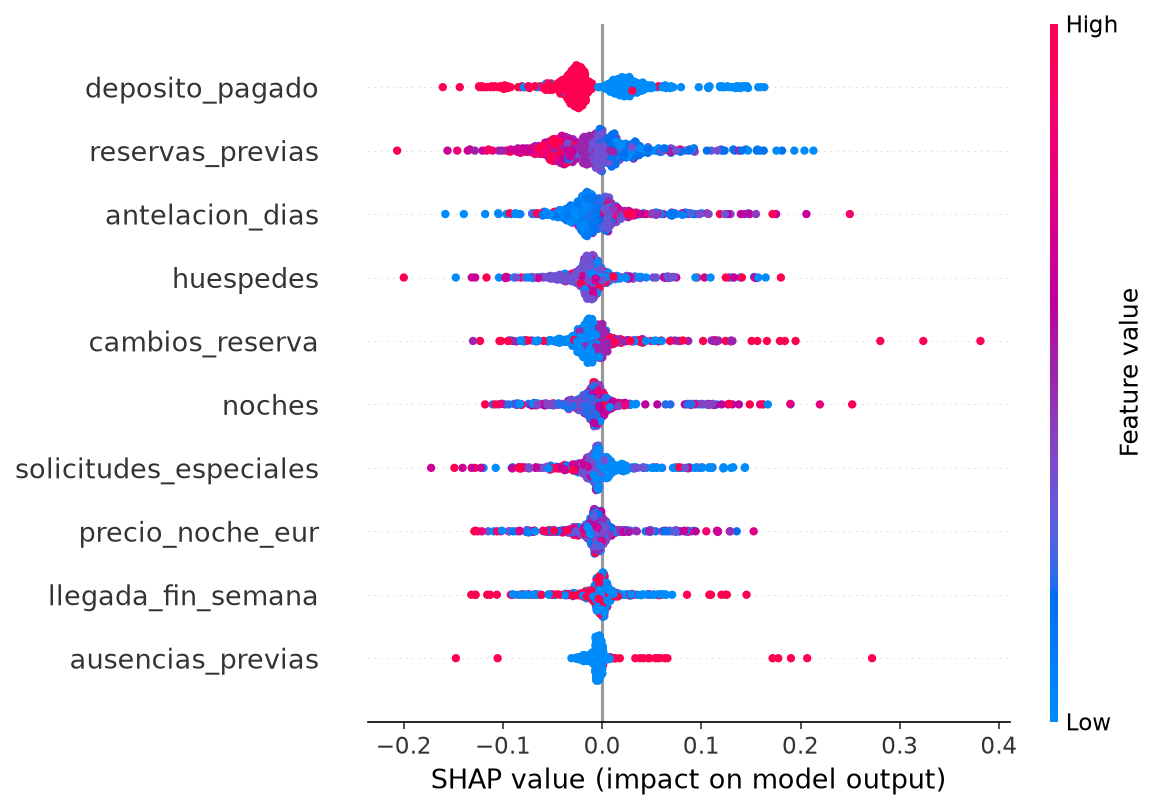

In [11]:
plt.figure(dpi=150)
shap.plots.beeswarm(shap_values_class_1, show=False)
plt.tight_layout()
plt.show()

Shap ordena automáticamente los resultados de más a menos significativos. 

Podríamos decir que en este caso uno de los dos algorítmos tiene mal la selección de variables más importantes (pues vemos ausencias_previas como la menos impactante, mientras que en nuestra selección de características de antes si que entró), pero realmente no tiene mucho sentido decir esto, ya que son fundamentos matemáticos diferentes, además de que en SHAP estamos involucrando un MLP, y en la selección una regresión logística. 

Sin embargo, si tiene sentido decir que tenemos más confianza ahora de decir que el número de reservas previas es bastante importante. Aquí podemos ver que hay varias consentraciones de puntos que se expanden a lo largo del eje x. Y se ve que hay una correlación en cuanto a mientras más bajo el valor de reservas previas, más positivo es el impacto (es decir, más probabilidad de que no se presente en la reserva).

También vemos que en este caso se le da más importancia a depósito pagado que antes. Antes, la diferencia entre reservas previas y depósito pagado era bastante grande, con depósito pagado teniendo la mitad de importancia que reservas previas. Aquí, sin embargo, se ven bastante igualadas, lo que tiene sentido, ya que es casi seguro que un invitado se presente a su reserva si pagó el depósito a que sino. Además, esta misma se ve que está casi perfectamente separada. 

Finalmente, ausencias_previas parece ser una variable importante por el nombre. Pero vemos que casi todos los puntos son bajos (o sea, igual a 0). Esto nos muestra la poca varianza que presenta esta variable, y explica por qué antes se descartó. 

In [12]:
y_pred = pipeline_mlp.predict_proba(X_test)
y_pred

array([[9.99999943e-01, 5.65437136e-08],
       [1.00000000e+00, 2.48053650e-11],
       [9.99798218e-01, 2.01781807e-04],
       ...,
       [9.99780346e-01, 2.19654423e-04],
       [9.99999998e-01, 1.72917130e-09],
       [1.00000000e+00, 9.70684949e-20]], shape=(1500, 2))

5
real 1
predicho 0.00048705205076777944


<Figure size 1920x1440 with 0 Axes>

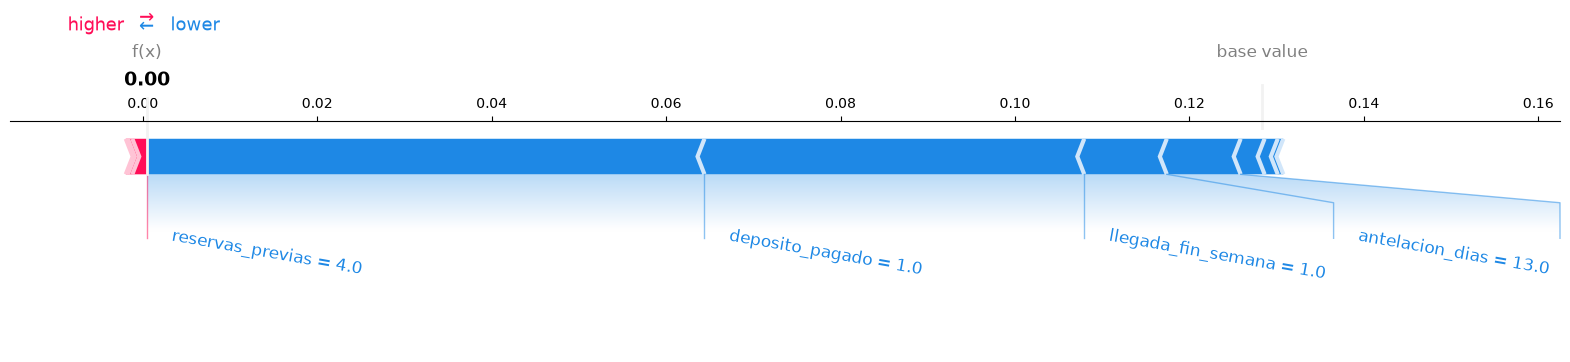

In [13]:
i = -1
n = 0
arr = y_test == 1

while n < 1:
    i += 1
    if arr.iloc[i]:
        n += 1

print(i)
idx = i
y_real = y_test.iloc[idx]

print("real", y_real)
print("predicho", y_pred[i, 1])

shap_val_single = explainer.shap_values(X_test.iloc[idx])

plt.figure(dpi=300)
shap.force_plot(
    base_value=explainer.expected_value[1],
    shap_values=shap_val_single[:, 1],
    features=X_test.iloc[[idx]],
    matplotlib=True,
    show=False,
    text_rotation=-10,
)

fig = plt.gcf()
ax = plt.gca()
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

plt.show()

13
real 1
predicho 0.9894446647266096


<Figure size 1920x1440 with 0 Axes>

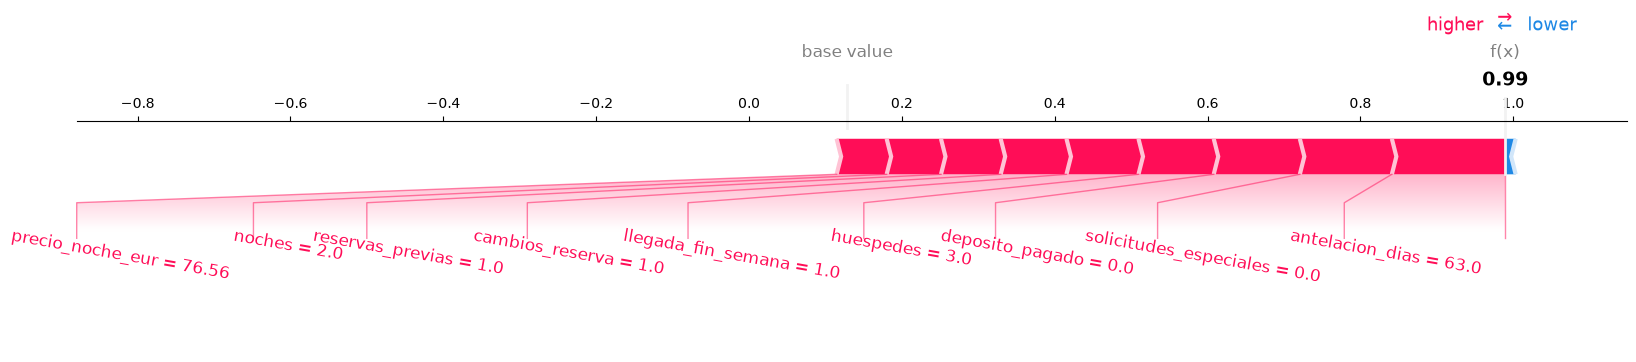

In [14]:
i = -1
n = 0
arr = y_test == 1

while n < 2:
    i += 1
    if arr.iloc[i]:
        n += 1

print(i)
idx = i
y_real = y_test.iloc[idx]

print("real", y_real)
print("predicho", y_pred[i, 1])

shap_val_single = explainer(X_test.iloc[idx])

plt.figure(dpi=300)
shap.force_plot(
    base_value=explainer.expected_value[1],
    shap_values=shap_val_single.values[:, 1],
    features=X_test.iloc[idx],
    matplotlib=True,
    show=False,
    text_rotation=-10,
)

fig = plt.gcf()
ax = plt.gca()
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

plt.show()

Este gráfico, force plot, nos muestra cómo cada feature individual aporta al cambio. Se empieza en el base value, que es la probabilidad de que una clase sea 1 (en este caso como es un problema binario, simplemente es la media de la clase), y cada feature aporta un valor, positivo si aumenta la probabilidad de clase 1 y negativo si la dismunuye, hasta llegar al valor predicho por el modelo, representado como f(x).  
Nuevamente, shap ordena el gráfico con las features de forma ascendente con respecto de f(x), es decir, del centro de las fuerzas hacia afuera, para facilitar su análisis.

He representado dos force plots. El primero un falso negativo y el segundo un verdadero positivo. Elegí hacerlo porque así podemos ver cosas curiosas del modelo. 

Primero el falso negativo. Es un ejemplo que honestamente parece un dato atípico. El gráfico nos muestra que habían 4 reservas previas, cliente fiel; había pagado el depósito, tiene qué perder; y era un fin de semana; menos probabilidad de que ocurra un altercado con el trabajo por ejemplo.

Luego el verdadero positivo. Aquí el modelo estaba casi seguro, con una predicción de 0.99. Da como facto positivo más importantes la antelación, que no hay solicitudes especiales y que no ha pagado el depósito. Luego, un poco menos importantes, aunque igual casi lo mismo que las demás, que hay 3 huéspedes, y que llega un fin de semana. 

Esto podría parecer una contradicción, pero es simplemente que en el modelo anterior el hecho de que llegue un fin de semana es tan irrelevante, pues el modelo está "hiperfijado" en que ya pagó la reserva y tiene 4 reservas anteriores, que queda simplemente como un residuo de las fuerzas negativas. 
